
$$
  \text{proj}_\mathbf{b}\mathbf{a} 
  = 
  \frac{\langle\mathbf{b},\mathbf{a}\rangle}
      {\langle \mathbf{b}, \mathbf{b} \rangle} 
  \mathbf{b}
$$

In [1]:
import numpy as np

a = np.array([2,3,4])
b = np.array([1,0,1])

proj_a_b = (np.dot(a,b) / np.dot(b,b)) * b



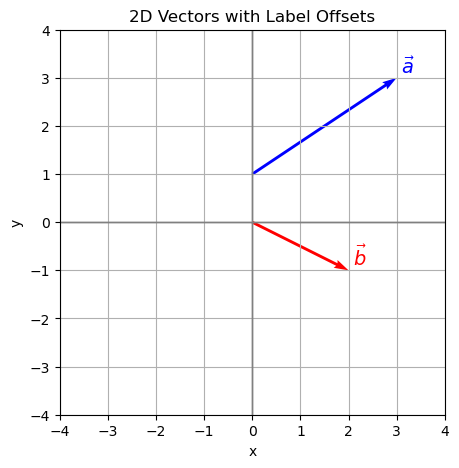

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from enum import Enum
class LineStyle(str, Enum):
    """
    Enumeration of common matplotlib line styles.
    """

    SOLID = '-'
    DASHED = '--'
    DOTTED = ':'
    DASH_DOT = '-.'
    NONE = ''  # for markers only

    def __str__(self):
        return self.value

class ColorHex(str, Enum):
    """
    Enumeration of common hex color codes (Matplotlib-compatible).
    These are perceptually distinct and publication-safe.
    """

    BLUE       = '#1f77b4'
    ORANGE     = '#ff7f0e'
    GREEN      = '#2ca02c'
    RED        = '#d62728'
    PURPLE     = '#9467bd'
    BROWN      = '#8c564b'
    PINK       = '#e377c2'
    GRAY       = '#7f7f7f'
    OLIVE      = '#bcbd22'
    CYAN       = '#17becf'
    BLACK      = '#000000'
    WHITE      = '#ffffff'

    def __str__(self):
        return self.value


def plot_vector(a, origin=(0,0), ax=None, color='blue', label=r'$\vec{a}$', linestyle=LineStyle.DOTTED, label_offset=(0.1,0.1)):
    """
    Plot a 2D vector using matplotlib with label offset.

    Parameters
    ----------
    a : array_like
        2D vector components [x, y].
    origin : tuple, optional
        Starting point of the vector (default: (0,0)).
    ax : matplotlib.axes.Axes, optional
        Existing axes to draw on. If None, creates a new figure.
    color : str, optional
        Color of the arrow.
    label : str, optional
        LaTeX label for the vector.
    label_offset : tuple, optional
        Offset for the label position (dx, dy) in data units.
    """

    a = np.array(a, dtype=float)
    ox, oy = origin

    if ax is None:
        fig, ax = plt.subplots(figsize=(5,5))

    # Draw coordinate axes
    ax.axhline(0, color='gray', lw=1)
    ax.axvline(0, color='gray', lw=1)

    # Draw vector
    ax.quiver(
      *origin, 
      *a,
      angles='xy', 
      scale_units='xy', 
      scale=1,
      linestyle=linestyle,
      color=color, linewidth=2)

    # Label with offset
    lx = ox + a[0] + label_offset[0]
    ly = oy + a[1] + label_offset[1]
    ax.text(lx, ly, label, fontsize=14, color=color)

    # Set limits symmetrically around origin


    return ax


# Example usage
fig, ax = plt.subplots(figsize=(5,5))
a = [3, 2]
a_origin = [0,1]
plot_vector([3, 2], origin=a_origin,ax=ax, color='blue', label=r'$\vec{a}$', label_offset=(0.1, 0.1))
plot_vector([2, -1], ax=ax, color='red', label=r'$\vec{b}$', label_offset=(0.1, 0.1))

lim = max(abs(a[0]), abs(a[1])) + 1
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect('equal')

ax.set_title('2D Vectors with Label Offsets')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid(True)
plt.show()


In [ ]:
import numpy as np

def calculate_projection(a: np.ndarray, b: np.ndarray) -> dict:
    """
    Compute the projection of vector a onto vector b.

    Parameters
    ----------
    a : np.ndarray
        Input vector to be projected (shape (n,) or (n,1)).
    b : np.ndarray
        Reference vector defining the projection direction (shape (n,) or (n,1)).

    Returns
    -------
    dict
        Dictionary containing:
            'proj_vec' : np.ndarray
                Vector projection of a onto b.
            'proj_scalar' : float
                Scalar projection (component of a along b).
            'perp_vec' : np.ndarray
                Component of a perpendicular to b.
    """

    # ensure 1D float arrays
    a = np.asarray(a, dtype=float).ravel()
    b = np.asarray(b, dtype=float).ravel()

    if np.allclose(b, 0):
        raise ValueError("Vector b must be nonzero for projection.")

    # inner products
    dot_ab = np.dot(a, b)
    dot_bb = np.dot(b, b)

    # scalar projection (magnitude)
    proj_scalar = dot_ab / np.linalg.norm(b)

    # vector projection (along b)
    proj_vec = (dot_ab / dot_bb) * b

    # perpendicular component
    perp_vec = a - proj_vec

    return {
        "proj_vec": proj_vec,
        "proj_scalar": proj_scalar,
        "perp_vec": perp_vec,
    }
